# Large Brain Model (LaBraM)

This notebook trains and evaluates the Large Brain Model (LaBraM) using pretrained foundation layers and LoRA adapters to decode binocular rivalry states (Congruent vs. Incongruent Pure).

### 📋 Large Brain Model (LaBraM) Pipeline Details
* **Input Data**: Raw EEG epochs in `.fif` format.
* **Preprocessing & Feature Extraction**:
  * **Class Balancing**: Random undersampling per subject.
  * **Resampling & Filtering**: All 60 electrodes; resampled to 128 Hz; full window (0.0s to 1.5s); IIR bandpassed (1.0–40.0 Hz).
  * **Sequence Padding**: Edge-padded along time axis to exactly 200 samples (`patch_size=200` turns the 1.5s trial into a single temporal patch).
  * **Standardization**: Per-trial and per-channel Z-score scaling.
* **Model Architecture**:
  * Pre-trained `InterpolatedLaBraM` backbone (spatial interpolation of channels, masked autoencoder pre-training).
  * LoRA injected into attention ("attn") and MLP ("mlp") modules with high regularization ($r=2$, $\alpha=4.0$, $dropout=0.2$, $weight\_decay=1e-2$).
  * Linear classifier head.
* **Training & Refitting**: AdamW optimizer ($lr=3e-5$), 2-stage automated refitting.
* **Evaluation**: 5-fold temporal stratified cross-validation.


### Large Brain Model (LaBraM) Downstream Adaptation Pipeline

LaBraM is pre-trained on massive EEG datasets. Here we adapt it to binary decoding with LoRA updates on self-attention projections, using a neural tokenizer and a summary token classification head.

```mermaid
graph TD
    A[Input Epochs: batch, channels, times] --> B[Reshape to batch*channels, 1, times]
    B --> C[Neural Tokenizer: Conv1D -> GELU -> Conv1D -> GELU]
    C --> D[Add Spatial & Temporal Positional Embeddings]
    D --> E[Flatten channels & patches to sequence]
    E --> F[Prepend Summary Token: summary_token]
    F --> G[LaBraM Transformer Blocks with LoRA adapters]
    G --> H[Extract summary_token state & LayerNorm]
    H --> I[Fully Connected Head with Dropout]
    I --> J[Classification Output: Congruent vs Incongruent Pure]
```

In [50]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_KAGGLE = False
IS_COLAB = 'google.colab' in sys.modules

if IS_KAGGLE:
    print('Detected Kaggle environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
elif IS_COLAB:
    print('Detected Google Colab environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount('/content/drive')

# Locate workspace source directory
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    # Dynamically find the unzipped dataset path
    dataset_root = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'tfg-nils-2026-dataset.zip' in files or 'br_analysis' in dirs:
            dataset_root = Path(root)
            break
    SRC_DIR = dataset_root if dataset_root else Path('/kaggle/input/nilsduranlaplaza/datasets/tfg-nils-2026-dataset')
elif IS_COLAB:
    SRC_DIR = Path('/content/drive/MyDrive/TFG_Nils_2026/03_Codi')
else:
    SRC_DIR = NOTEBOOK_DIR.parent

src_dir_str = str(SRC_DIR)
sys.path = [p for p in sys.path if p != src_dir_str]
sys.path.insert(0, src_dir_str)

for module_name in list(sys.modules):
    if module_name == "br_analysis" or module_name.startswith("br_analysis."):
        del sys.modules[module_name]

print(f'Using source directory: {SRC_DIR}')

Detected Google Colab environment. Installing dependencies...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using source directory: /content/drive/MyDrive/TFG_Nils_2026/03_Codi


## Task And Environment Setup

In [51]:
import numpy as np
import pandas as pd
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    chronological_group_labels,
    stratified_group_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
    input_attribution_summary,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)
from braindecode.models import InterpolatedLaBraM

TASK_TAG = "c_vs_ip_labram"
paths = detect_project_paths("c_vs_i_labram")
task_name = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
task = get_task_config(task_name, paths.analysis_root)

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)

Working Paths:
  Cache: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_labram/cache
  Tables: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_labram/tables
  Figures: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_labram/figures


## Load Epochs And Pad Layout

In [52]:
spec = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = "P057"
ch_names = list(dataset.channel_names)
times = dataset.times
chs_info = dataset.chs_info
sfreq = 128.0

# Use native epoch length
# Pad to 200 to match the pretrained model's patch_size (200) and preserve embed_dim=200
TARGET_LEN = 200
X = np.pad(X_raw, ((0, 0), (0, 0), (0, TARGET_LEN - X_raw.shape[-1])), mode="edge")

print(f"X shape: {X.shape} (trials, channels, times)")
print(f"Classes: {np.bincount(y)}")

Loading preprocessed dataset from cache: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/cache/dataset_c_vs_ip_subj24_bp1.0_40.0_sf128.0_win0.0_1.5_pkall.joblib
X shape: (5870, 60, 200) (trials, channels, times)
Classes: [2935 2935]


## LaBraM Model Definition & Configuration

In [53]:
def make_model(lora_r=2):
    ch_names = [ch["ch_name"] for ch in chs_info]
    info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types="eeg")
    montage = mne.channels.make_standard_montage("standard_1005")
    info.set_montage(montage)

    from huggingface_hub import hf_hub_download

    # Instantiate model directly to prevent strict loading failures in from_pretrained
    model = InterpolatedLaBraM(
        chs_info=info["chs"],
        n_times=TARGET_LEN,
        n_outputs=2,
        patch_size=200,
    )
    # Download and load pretrained weights manually with our custom load_backbone_weights
    checkpoint_path = None
    if IS_KAGGLE:
        for root, dirs, files in os.walk("/kaggle/input"):
            if "model.safetensors" in files and "labram" in root.lower():
                checkpoint_path = Path(root) / "model.safetensors"
                break
    if checkpoint_path is None:
        checkpoint_path = hf_hub_download(
            repo_id="braindecode/labram-pretrained",
            filename="model.safetensors",
        )
    load_backbone_weights(model, Path(checkpoint_path), strict=False)

    prepare_lora_backbone(
        model,
        include_substrings=("attn", "mlp"),
        exclude_substrings=("head", "classifier", "interpolation_layer"),
        r=lora_r,
        alpha=4.0,
        dropout=0.2,
        train_classifier=True,
    )

    if hasattr(model, "get_classifier"):
        for p in model.get_classifier().parameters():
            p.requires_grad = True
    return model


train_cfg = TorchTrainConfig(
    epochs=50,
    batch_size=8,
    lr=3e-5,
    weight_decay=1e-2,
    patience=15,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    early_stopping_metric="val_balanced_acc",
    device=DEVICE,
    progress=True,
)

## 3. Cohort-Wide Training (LoRA Fine-tuning)

We train the LoRA fine-tuned LaBraM model across all 24 subjects individually and cache the results.

In [54]:
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print("Loading LaBraM cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running LaBraM cohort-wide cross-validation with LoRA adapters...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=False,
        early_stopping_metric=train_cfg.early_stopping_metric,
    )

    for sub in subject_ids:
        subj_metrics_path = paths.cache_dir / f"metrics_{TASK_TAG}_sub{sub}.csv"
        if subj_metrics_path.exists():
            print(f"Loading cached metrics for subject {sub}...")
            labram_metrics = pd.read_csv(subj_metrics_path)
        else:
            print(f"Training/Evaluating subject {sub}...")
            import gc

            gc.collect()
            torch.cuda.empty_cache()
            labram_metrics, _ = cross_validate_torch_model(
                X,
                y,
                make_model,
                silent_cfg,
                subjects=subjects,
                subject_id=sub,
                save_weights_dir=paths.cache_dir,
                weights_prefix=f"{TASK_TAG}_sub{sub}",
                load_weights=True,
            )
            labram_metrics.to_csv(subj_metrics_path, index=False)

        cohort_results.append(
            {
                "subject": sub,
                "labram_acc": labram_metrics["test_acc"].mean(),
                "labram_auc": labram_metrics["test_auc"].mean(),
                "labram_bal_acc": labram_metrics["test_balanced_acc"].mean(),
            }
        )

        for idx, row in labram_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "LaBraM",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)
    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")


# Global Cohort CV Summary (mean ± std)
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
print("=" * 50)
for model_name in df_cohort_folds["model"].unique():
    model_df = df_cohort_folds[df_cohort_folds["model"] == model_name]
    print(f"Model: {model_name}")
    for f in sorted(model_df["fold"].unique()):
        fold_df = model_df[model_df["fold"] == f]
        mean_f = fold_df["test_acc"].mean()
        std_f = fold_df["test_acc"].std()
        print(f"  Fold {f} Accuracy: {mean_f:.4f} ± {std_f:.4f}")
    mean_cv = model_df["test_acc"].mean()
    std_cv = model_df["test_acc"].std()
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")

Loading LaBraM cohort metrics from cache...

GLOBAL COHORT CROSS-VALIDATION SUMMARY
Model: LaBraM
  Fold 1 Accuracy: 0.4875 ± 0.0824
  Fold 2 Accuracy: 0.4711 ± 0.1291
  Fold 3 Accuracy: 0.4982 ± 0.0995
  Fold 4 Accuracy: 0.5079 ± 0.0864
  Fold 5 Accuracy: 0.4775 ± 0.1539
  Average CV Accuracy: 0.4884 ± 0.1125



## 3.5 Cohort-Wide Predictions Extraction

We extract model predictions across all subjects and folds once, caching them in memory so we don't have to reload models in subsequent sections.

In [55]:
# Export versioned out-of-fold predictions and compact attributions for cross-model comparison
OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"
OOF_CV_STRATEGY = "stratified_group_kfold_development_only"
ATTRIBUTION_CACHE_VERSION = "input_integrated_gradients_v1"
ATTRIBUTION_MODE = "integrated_gradients"
ATTRIBUTION_IG_STEPS = 8
HOLDOUT_FRAC = 0.20

all_y_true = []
all_probs = []
subject_y_trues = {}
subject_y_probs = {}
subject_spatial_saliency = {}
subject_temporal_saliency = {}
subject_saliency_n = {}
subject_fold_predictions = {}

device = torch.device(DEVICE)
attr_batch_size = min(8, train_cfg.batch_size)


def _cache_has_current_attributions(path):
    if not path.exists():
        return False
    try:
        with np.load(path, allow_pickle=True) as data:
            return str(np.asarray(data.get("_saliency_version", "")).item()) == ATTRIBUTION_CACHE_VERSION
    except Exception:
        return False


def _weighted_mean(items):
    if not items:
        return None
    values, counts = zip(*items)
    return np.average(np.stack(values), axis=0, weights=np.asarray(counts, dtype=float)).astype(np.float32)

def _infer_lora_rank(weights_path):
    state = torch.load(weights_path, map_location="cpu")
    for key, value in state.items():
        if key.endswith("lora_a.weight"):
            return int(value.shape[0])
    return 2


task_name_lc = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
model_name_lc = "labram"
comp_paths = detect_project_paths("cross_model_comparison")
out_path = comp_paths.cache_dir / f"oof_predictions_{task_name_lc}_{model_name_lc}.npz"

if _cache_has_current_attributions(out_path):
    print(f"[OOF OK] Current attribution cache already exists: {out_path}")
else:
    print("Extracting LaBraM cohort predictions and attributions across all subjects and folds...")
    for sub in subject_ids:
        mask = subjects == sub
        splits = list(
            stratified_group_splits(
                y[mask],
                groups=chronological_group_labels(int(mask.sum())),
                n_splits=train_cfg.n_splits,
            )
        )
        X_sub = X[mask]
        y_sub = y[mask]

        sub_y_true = []
        sub_y_prob = []
        sub_spatial = []
        sub_temporal = []
        subject_fold_predictions[sub] = {}

        for fold, (train_idx, test_idx) in enumerate(splits, start=1):
            _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
            y_test = y_sub[test_idx]
            weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
            if not weights_path.exists():
                print(f"[OOF SKIP] {weights_path.name} missing")
                continue

            checkpoint = torch.load(weights_path, map_location=device)
            model = make_model(lora_r=_infer_lora_rank(weights_path)).to(device)
            model.load_state_dict(checkpoint, strict=False)
            model.eval()

            loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
            _, _, _, y_true_arr, p = _evaluate(model, loader, device)
            all_y_true.extend(y_true_arr)
            all_probs.extend(p)
            sub_y_true.extend(y_true_arr)
            sub_y_prob.extend(p)
            subject_fold_predictions[sub][fold] = (y_true_arr, p)

            try:
                sp, te, n_attr = input_attribution_summary(
                    model,
                    X_test,
                    y_test,
                    device=device,
                    batch_size=attr_batch_size,
                    mode=ATTRIBUTION_MODE,
                    ig_steps=ATTRIBUTION_IG_STEPS,
                    only_correct=True,
                    spatial_axis=1,
                    temporal_axis=2,
                )
                sub_spatial.append((sp, n_attr))
                sub_temporal.append((te, n_attr))
            except Exception as exc:
                print(f"[ATTR SKIP] {weights_path.name}: {exc}")
            finally:
                del model, loader
                import gc
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        if sub_y_true:
            subject_y_trues[sub] = np.asarray(sub_y_true)
            subject_y_probs[sub] = np.asarray(sub_y_prob)
        sp_mean = _weighted_mean(sub_spatial)
        te_mean = _weighted_mean(sub_temporal)
        if sp_mean is not None and te_mean is not None:
            subject_spatial_saliency[sub] = sp_mean
            subject_temporal_saliency[sub] = te_mean
            subject_saliency_n[sub] = int(sum(n for _, n in sub_spatial))

    oof_save_dict = {}
    for sub in subject_ids:
        if sub in subject_y_trues and sub in subject_y_probs:
            oof_save_dict[f"{sub}_y_true"] = subject_y_trues[sub]
            oof_save_dict[f"{sub}_prob"] = subject_y_probs[sub]
        if sub in subject_spatial_saliency and sub in subject_temporal_saliency:
            oof_save_dict[f"{sub}_spatial_saliency"] = subject_spatial_saliency[sub]
            oof_save_dict[f"{sub}_temporal_saliency"] = subject_temporal_saliency[sub]
            oof_save_dict[f"{sub}_saliency_n"] = np.array(subject_saliency_n[sub])

    if not oof_save_dict:
        print("[OOF SKIP] No LaBraM predictions collected; cache not written")
    else:
        oof_save_dict["_cache_version"] = np.array(OOF_CACHE_VERSION)
        oof_save_dict["_cv_strategy"] = np.array(OOF_CV_STRATEGY)
        oof_save_dict["_holdout_frac"] = np.array(HOLDOUT_FRAC if "HOLDOUT_FRAC" in globals() else 0.20)
        oof_save_dict["_saliency_version"] = np.array(ATTRIBUTION_CACHE_VERSION)
        oof_save_dict["_saliency_method"] = np.array(ATTRIBUTION_MODE)
        oof_save_dict["_saliency_ig_steps"] = np.array(ATTRIBUTION_IG_STEPS)
        oof_save_dict["_saliency_sample_filter"] = np.array("correct_predictions_or_all_if_none")
        out_path.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(out_path, **oof_save_dict)
        print(f"Saved versioned OOF + attribution cache to: {out_path}")


Extracting cohort predictions across all subjects and folds...
Loading pretrained model from /root/.cache/huggingface/hub/models--braindecode--labram-pretrained/snapshots/0563b6c626e7b40d9a36653b763715db94d945d7/model.safetensors...


## 4. Single-Subject Detailed Performance Comparison (P057)

=== LaBraM Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.35      0.28      0.31        78
Incongruent_Pure       0.57      0.65      0.61       114

        accuracy                           0.50       192
       macro avg       0.46      0.47      0.46       192
    weighted avg       0.48      0.50      0.49       192



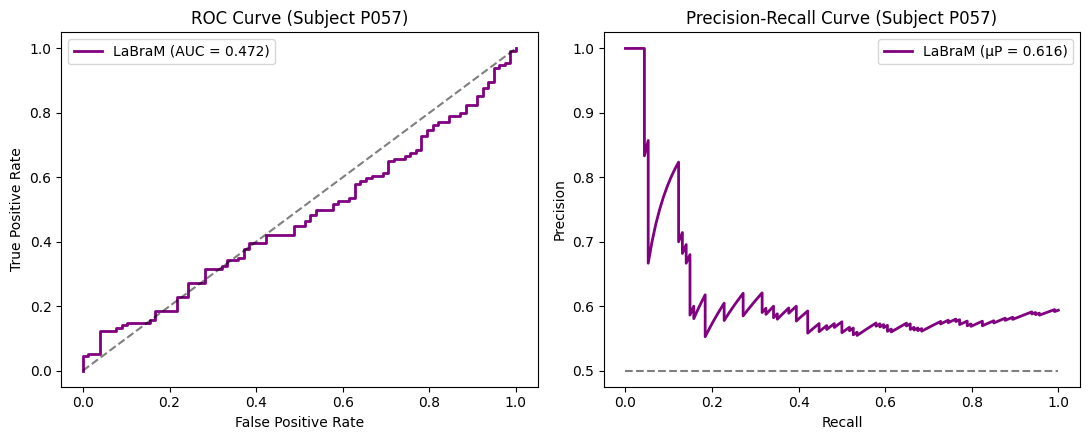

In [56]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

# Extract P057-specific predictions from the cohort predictions
y_true_all = subject_y_trues[SUBJECT_ID]
probs = subject_y_probs[SUBJECT_ID]
preds = (probs >= 0.5).astype(int)

print("=== LaBraM Classification Report (Subject P057) ===")
print(classification_report(y_true_all, preds, target_names=[task.class_0, task.class_1], zero_division=0.0))

# Plot ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_true_all, probs)
ax_roc.plot(fpr, tpr, label=f"LaBraM (AUC = {auc(fpr, tpr):.3f})", color="purple", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title("ROC Curve (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(y_true_all, probs)
ax_pr.plot(rec, prec, label=f"LaBraM (μP = {auc(rec, prec):.3f})", color="purple", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"roc_pr_{TASK_TAG}_P057.png", dpi=180, bbox_inches="tight")
plt.show()

## Final Holdout ONCE

This cell trains the frozen model configuration on each subject's development set and evaluates only the reserved final 20% holdout. The CSV produced here is the only deep-learning result that should feed the thesis final test-set table.

In [57]:
MODEL_NAME = "LaBraM"
MODEL_DISPLAY = "LaBraM"

from br_analysis.torch_training import fit_one_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

FINAL_TEST_ALREADY_USED = False
final_file = paths.tables_dir / f"final_holdout_{TASK_TAG}.csv"

if final_file.exists():
    print("Loading final holdout results from cache:", final_file)
    df_final_holdout = pd.read_csv(final_file)
elif FINAL_TEST_ALREADY_USED:
    print("FINAL_TEST_ALREADY_USED=True; skipping final holdout evaluation.")
else:
    rows = []
    final_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=train_cfg.progress,
        early_stopping_metric=train_cfg.early_stopping_metric,
        refit=True,
    )

    def dev_holdout_idx(n, holdout_frac=0.2):
        cutoff = int(np.floor((1.0 - holdout_frac) * n))
        cutoff = max(1, min(cutoff, n - 1))
        return np.arange(cutoff), np.arange(cutoff, n)

    for sub in subject_ids:
        print(f"Final holdout {MODEL_DISPLAY} subject {sub}...")
        mask = subjects == sub
        y_sub = y[mask]
        X_sub = X[mask]
        dev_idx, holdout_idx = dev_holdout_idx(len(y_sub))
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[holdout_idx])) < 2:
            print(f"  Skipping {sub}: holdout lacks both classes")
            continue
        X_dev, X_hold = standardize_train_test(X_sub[dev_idx], X_sub[holdout_idx])
        metrics, _, y_true, probs = fit_one_split(
            make_model,
            X_dev,
            y_sub[dev_idx],
            X_hold,
            y_sub[holdout_idx],
            final_cfg,
            save_path=paths.cache_dir / f"final_holdout_{TASK_TAG}_sub{sub}.pt",
        )
        pred = (probs >= 0.5).astype(int)
        try:
            auc_val = roc_auc_score(y_true, probs)
        except ValueError:
            auc_val = np.nan
        rows.append(
            {
                "Task": task.name,
                "Subject": sub,
                "Model": MODEL_NAME,
                "Accuracy": accuracy_score(y_true, pred),
                "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
                "ROC AUC": auc_val,
                "N Test": len(y_true),
                "Source": "final_holdout",
            }
        )
    df_final_holdout = pd.DataFrame(rows)
    df_final_holdout.to_csv(final_file, index=False)
    print("Saved final holdout results to:", final_file)

summary = (
    df_final_holdout.groupby("Model")
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        std_accuracy=("Accuracy", "std"),
        mean_auc=("ROC AUC", "mean"),
        balanced_accuracy=("Balanced Accuracy", "mean"),
        n_subjects=("Subject", "nunique"),
        n_test_trials=("N Test", "sum"),
    )
    .reset_index()
)
print(summary.to_string(index=False))

Loading final holdout results from cache: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_labram/tables/final_holdout_c_vs_ip_labram.csv
 Model  mean_accuracy  std_accuracy  mean_auc  balanced_accuracy  n_subjects  n_test_trials
LaBraM       0.525962      0.103135  0.538478           0.519336          24           1184
